# 04 - Association Rule Mining

This module applies market basket analysis to the Washington State EV registration dataset to discover co-occurrence patterns between manufacturers, EV types, and county cluster membership. Each county is treated as a transaction and the manufacturers present in that county are the items. Three analyses are performed: make co-occurrence across counties, make-to-EV-type associations, and make-to-cluster associations.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from mlxtend.frequent_patterns import apriori, association_rules
from mlxtend.preprocessing import TransactionEncoder
import os

os.makedirs('outputs/figures', exist_ok=True)
os.makedirs('outputs/results', exist_ok=True)

plt.rcParams['figure.dpi'] = 150
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
sns.set_style('whitegrid')

In [2]:
# Load the cleaned vehicle-level data and county cluster assignments
df = pd.read_csv('outputs/results/cleaned_data.csv')
county_clustered = pd.read_csv('outputs/results/county_clustered.csv')

cluster_labels = {
    0: 'Low Adoption, BEV-Leaning',
    1: 'Low Adoption, PHEV-Dominant',
    2: 'High Adoption, Mixed Fleet',
    3: 'King County Mega Hub'
}
county_clustered['Cluster_Label'] = county_clustered['Cluster'].map(cluster_labels)

print(f'Vehicle records: {len(df):,}')
print(f'Counties: {df["County"].nunique()}')
print(f'Unique makes: {df["Make"].nunique()}')
print(f'\nCleaned data columns: {list(df.columns)}')
print(f'County clustered columns: {list(county_clustered.columns)}')

Vehicle records: 271,103
Counties: 246
Unique makes: 47

Cleaned data columns: ['County', 'City', 'Postal Code', 'Model Year', 'Make', 'Model', 'Electric Vehicle Type', 'Clean Alternative Fuel Vehicle (CAFV) Eligibility', 'Electric Range', 'Legislative District', 'Electric Utility', 'CAFV_Category', 'EV_Type', 'Range_Category', 'EV_Era']
County clustered columns: ['County', 'Total_EVs', 'BEV_Count', 'PHEV_Count', 'Avg_Electric_Range', 'Unique_Makes', 'Unique_Models', 'Most_Common_Make', 'Avg_Model_Year', 'BEV_Proportion', 'PHEV_Proportion', 'Cluster', 'Cluster_Label']


/var/folders/c5/sg761v556rj4q__1mdbdcfs80000gn/T/ipykernel_6024/3724736074.py:2: DtypeWarning: Columns (0: Legislative District) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('outputs/results/cleaned_data.csv')


In [3]:
# Build the county-level transaction basket: each county is one transaction,
# items are the unique Makes present in that county
county_makes = df.groupby('County')['Make'].apply(lambda x: list(x.unique())).reset_index()
county_makes.columns = ['County', 'Makes']

# Merge cluster labels onto the basket so we can filter by cluster later
county_makes = county_makes.merge(county_clustered[['County', 'Cluster', 'Cluster_Label']], on='County', how='left')

print(f'Transactions (counties): {len(county_makes)}')
print(f'\nMakes per county (summary):')
basket_lengths = county_makes['Makes'].apply(len)
print(basket_lengths.describe().round(1))

Transactions (counties): 246

Makes per county (summary):
count    246.0
mean       6.3
std       10.6
min        1.0
25%        1.0
50%        2.0
75%        4.0
max       44.0
Name: Makes, dtype: float64


In [4]:
# Encode the transaction list into a boolean matrix for Apriori
te = TransactionEncoder()
te_array = te.fit_transform(county_makes['Makes'])
basket_df = pd.DataFrame(te_array, columns=te.columns_)

print(f'Transaction matrix shape: {basket_df.shape}')
print(f'Items (unique makes): {basket_df.shape[1]}')

# Calculate item support across all counties to understand coverage
item_support = basket_df.mean().sort_values(ascending=False)
print(f'\nTop 15 makes by county coverage (support):')
print(item_support.head(15).round(3).to_string())

# Run Apriori limited to pairs (max_len=2) to avoid memory exhaustion
# Triplets and longer itemsets are rarely interpretable and blow up combinatorially with 47 items
frequent_itemsets = apriori(basket_df, min_support=0.05, use_colnames=True, max_len=2)
frequent_itemsets['length'] = frequent_itemsets['itemsets'].apply(len)

print(f'\nFrequent itemsets found: {len(frequent_itemsets)}')
print(f'\nItemset size breakdown:')
print(frequent_itemsets['length'].value_counts().sort_index())

# Generate association rules with lift > 1
rules = association_rules(frequent_itemsets, metric='lift', min_threshold=1.0)
rules = rules.sort_values('lift', ascending=False).reset_index(drop=True)

print(f'\nTotal rules generated: {len(rules)}')
print(f'Rules with lift > 1.5: {(rules["lift"] > 1.5).sum()}')
print(f'Rules with lift > 2.0: {(rules["lift"] > 2.0).sum()}')

Transaction matrix shape: (246, 47)
Items (unique makes): 47

Top 15 makes by county coverage (support):
TESLA            0.768
JEEP             0.268
TOYOTA           0.264
BMW              0.244
CHEVROLET        0.244
FORD             0.244
RIVIAN           0.228
HYUNDAI          0.224
KIA              0.215
CHRYSLER         0.215
NISSAN           0.203
VOLVO            0.203
VOLKSWAGEN       0.187
SUBARU           0.163
MERCEDES-BENZ    0.159

Frequent itemsets found: 656

Itemset size breakdown:
length
1     36
2    620
Name: count, dtype: int64

Total rules generated: 1240
Rules with lift > 1.5: 1170
Rules with lift > 2.0: 1170


In [5]:
# Separate Tesla rules from non-Tesla rules
rules_str = rules.copy()
rules_str['antecedents_str'] = rules_str['antecedents'].apply(lambda x: ', '.join(sorted(x)))
rules_str['consequents_str'] = rules_str['consequents'].apply(lambda x: ', '.join(sorted(x)))
rules_str['rule_str'] = rules_str['antecedents_str'] + ' -> ' + rules_str['consequents_str']

non_tesla_rules = rules_str[
    ~rules_str['antecedents_str'].str.contains('TESLA') &
    ~rules_str['consequents_str'].str.contains('TESLA')
].copy()

tesla_rules = rules_str[
    rules_str['antecedents_str'].str.contains('TESLA') |
    rules_str['consequents_str'].str.contains('TESLA')
].copy()

print(f'Rules involving Tesla: {len(tesla_rules)}')
print(f'Rules not involving Tesla: {len(non_tesla_rules)}')
print(f'\nTop 10 non-Tesla rules by lift:')
print(non_tesla_rules[['antecedents_str', 'consequents_str', 'support', 'confidence', 'lift']]
      .head(10).round(3).to_string(index=False))

Rules involving Tesla: 70
Rules not involving Tesla: 1170

Top 10 non-Tesla rules by lift:
antecedents_str consequents_str  support  confidence   lift
         JAGUAR           ACURA    0.053       1.000 10.696
          ACURA          JAGUAR    0.053       0.565 10.696
         FISKER           SMART    0.069       0.944 10.561
          SMART          FISKER    0.069       0.773 10.561
         FISKER      ALFA ROMEO    0.053       0.722 10.451
     ALFA ROMEO          FISKER    0.053       0.765 10.451
     LAND ROVER           ACURA    0.077       0.950 10.161
          ACURA      LAND ROVER    0.077       0.826 10.161
     LAND ROVER         GENESIS    0.069       0.850  9.957
        GENESIS      LAND ROVER    0.069       0.810  9.957


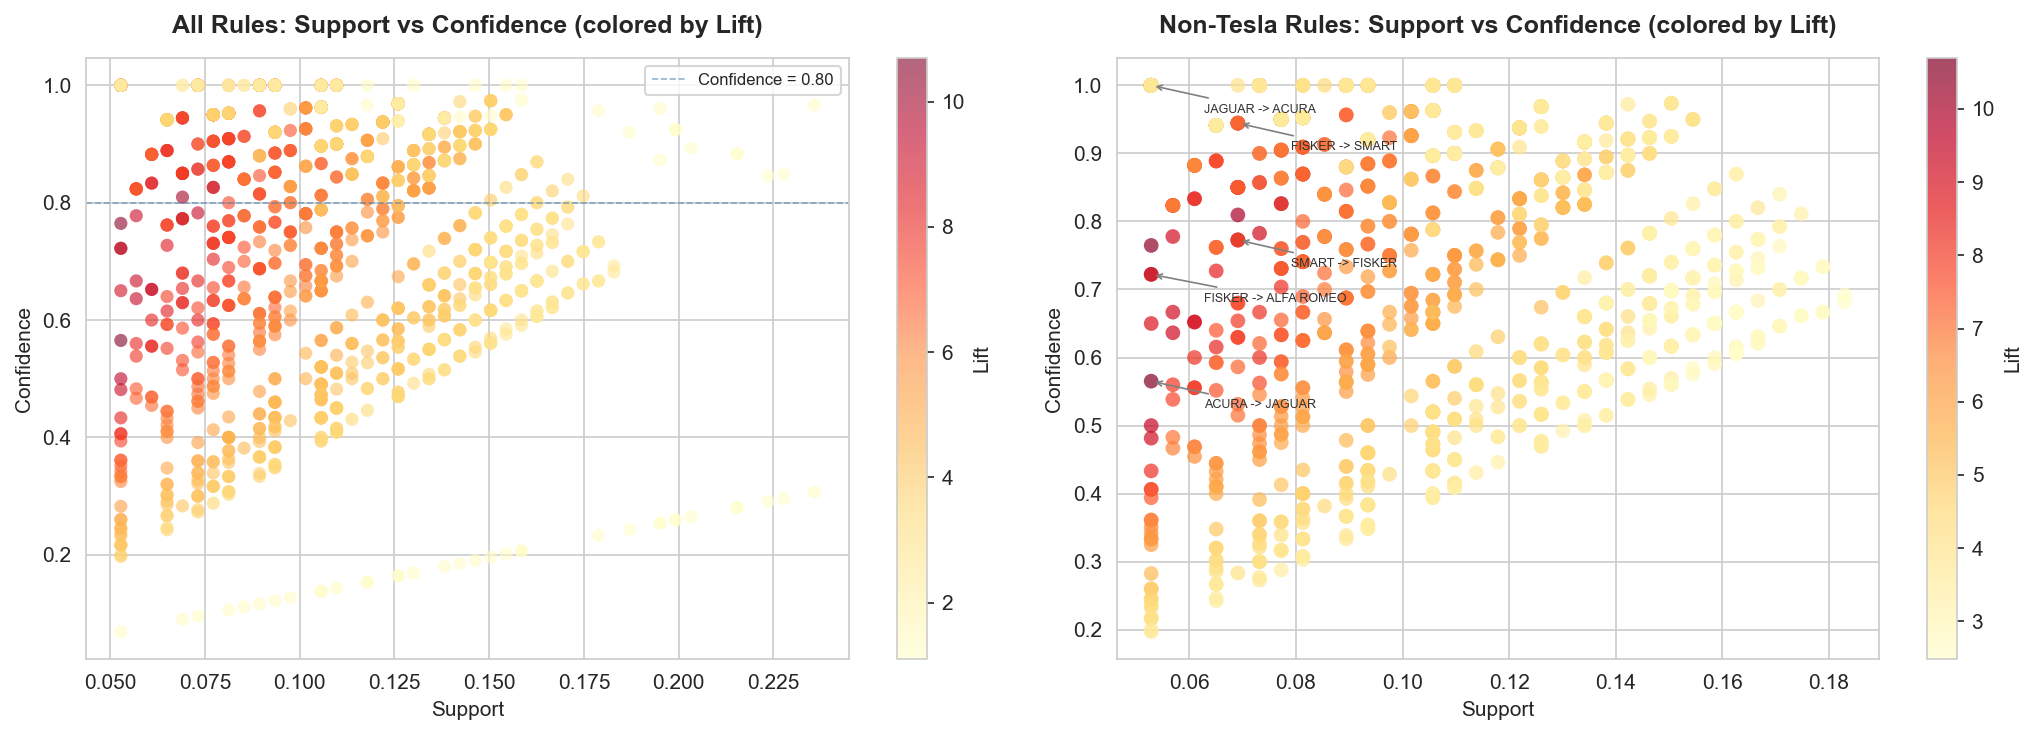

Figure saved: outputs/figures/association_rules_scatter.png


In [6]:
# Figure 1: Support vs Confidence scatter plot colored by lift
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left panel: all rules
sc1 = axes[0].scatter(
    rules_str['support'], rules_str['confidence'],
    c=rules_str['lift'], cmap='YlOrRd', alpha=0.6, s=40, edgecolors='none'
)
plt.colorbar(sc1, ax=axes[0], label='Lift')
axes[0].set_xlabel('Support')
axes[0].set_ylabel('Confidence')
axes[0].set_title('All Rules: Support vs Confidence (colored by Lift)', fontweight='bold', pad=12)
axes[0].axhline(0.8, color='steelblue', linestyle='--', linewidth=0.8, alpha=0.6, label='Confidence = 0.80')
axes[0].legend(fontsize=8)

# Right panel: non-Tesla rules only
sc2 = axes[1].scatter(
    non_tesla_rules['support'], non_tesla_rules['confidence'],
    c=non_tesla_rules['lift'], cmap='YlOrRd', alpha=0.7, s=50, edgecolors='none'
)
plt.colorbar(sc2, ax=axes[1], label='Lift')

# Label the top 5 high-lift non-Tesla rules
top5 = non_tesla_rules.nlargest(5, 'lift')
for _, row in top5.iterrows():
    label = f"{row['antecedents_str']} -> {row['consequents_str']}"
    if len(label) > 40:
        label = label[:38] + '...'
    axes[1].annotate(
        label, xy=(row['support'], row['confidence']),
        xytext=(row['support'] + 0.01, row['confidence'] - 0.04),
        fontsize=6, color='#333333',
        arrowprops=dict(arrowstyle='->', color='gray', lw=0.8)
    )

axes[1].set_xlabel('Support')
axes[1].set_ylabel('Confidence')
axes[1].set_title('Non-Tesla Rules: Support vs Confidence (colored by Lift)', fontweight='bold', pad=12)

plt.tight_layout()
plt.savefig('outputs/figures/association_rules_scatter.png', bbox_inches='tight')
plt.show()
print('Figure saved: outputs/figures/association_rules_scatter.png')

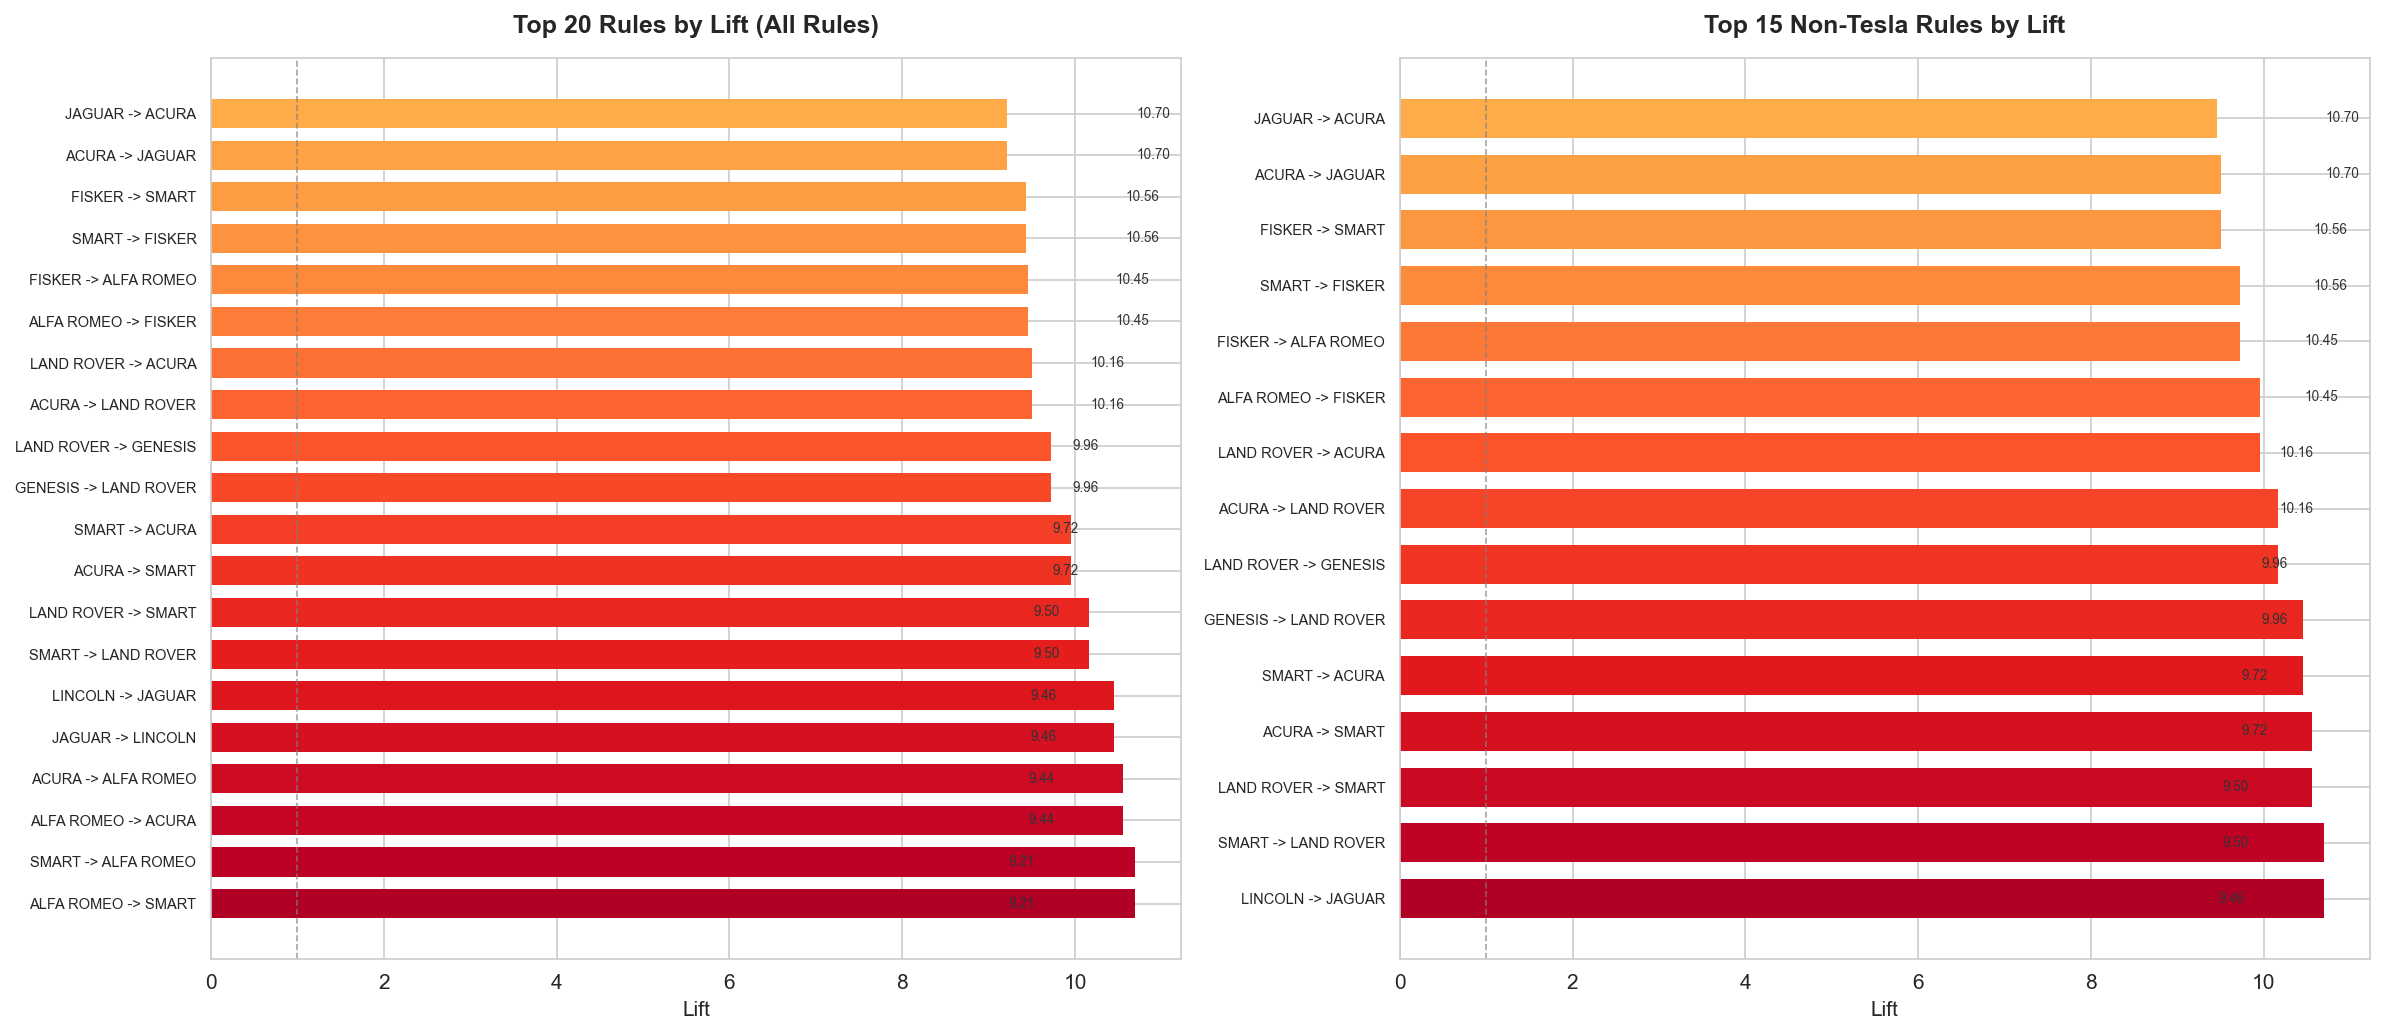

Figure saved: outputs/figures/top_rules_by_lift.png


In [7]:
# Figure 2: Top 20 rules by lift — horizontal bar chart
top20_all = rules_str.nlargest(20, 'lift')
top15_non_tesla = non_tesla_rules.nlargest(15, 'lift')

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

for ax, data, title_text in [
    (axes[0], top20_all, 'Top 20 Rules by Lift (All Rules)'),
    (axes[1], top15_non_tesla, 'Top 15 Non-Tesla Rules by Lift')
]:
    labels = [f"{r['antecedents_str']} -> {r['consequents_str']}" for _, r in data.iterrows()]
    labels = [l[:55] + '...' if len(l) > 55 else l for l in labels]
    colors = plt.cm.YlOrRd(np.linspace(0.4, 0.9, len(data)))
    bars = ax.barh(range(len(data)), data['lift'].values, color=colors[::-1], edgecolor='none', height=0.7)
    ax.set_yticks(range(len(data)))
    ax.set_yticklabels(labels[::-1], fontsize=7)
    ax.set_xlabel('Lift', fontsize=10)
    ax.set_title(title_text, fontweight='bold', pad=12)
    ax.axvline(1.0, color='gray', linestyle='--', linewidth=0.8, alpha=0.7)
    for i, (bar, val) in enumerate(zip(bars, data['lift'].values[::-1])):
        ax.text(val + 0.02, bar.get_y() + bar.get_height() / 2,
                f'{val:.2f}', va='center', fontsize=6.5, color='#333333')

plt.tight_layout()
plt.savefig('outputs/figures/top_rules_by_lift.png', bbox_inches='tight')
plt.show()
print('Figure saved: outputs/figures/top_rules_by_lift.png')

In [8]:
# Build augmented basket with dominant EV type per county
county_type = county_clustered[['County', 'Cluster', 'Cluster_Label', 'BEV_Proportion']].copy()
county_type['Dominant_Type'] = county_type['BEV_Proportion'].apply(
    lambda x: 'TYPE_BEV' if x >= 0.5 else 'TYPE_PHEV'
)

county_makes_type = county_makes.merge(county_type[['County', 'Dominant_Type']], on='County', how='left')
county_makes_type['Items'] = county_makes_type.apply(
    lambda row: row['Makes'] + [row['Dominant_Type']] if pd.notna(row['Dominant_Type']) else row['Makes'],
    axis=1
)

print(f'Counties with BEV-dominant label: {(county_type["Dominant_Type"] == "TYPE_BEV").sum()}')
print(f'Counties with PHEV-dominant label: {(county_type["Dominant_Type"] == "TYPE_PHEV").sum()}')

# Encode and run Apriori
te2 = TransactionEncoder()
te2_array = te2.fit_transform(county_makes_type['Items'])
basket_type_df = pd.DataFrame(te2_array, columns=te2.columns_)

frequent_type = apriori(basket_type_df, min_support=0.05, use_colnames=True, max_len=2)
rules_type = association_rules(frequent_type, metric='lift', min_threshold=1.0)
rules_type = rules_type.sort_values('lift', ascending=False).reset_index(drop=True)

rules_type['antecedents_str'] = rules_type['antecedents'].apply(lambda x: ', '.join(sorted(x)))
rules_type['consequents_str'] = rules_type['consequents'].apply(lambda x: ', '.join(sorted(x)))

# Extract rules where the consequent is a TYPE label
type_rules = rules_type[
    rules_type['consequents_str'].isin(['TYPE_BEV', 'TYPE_PHEV']) &
    ~rules_type['antecedents_str'].str.contains('TYPE_')
].copy()

print(f'\nRules predicting EV type from make: {len(type_rules)}')
print(f'\nTop 15 make -> type rules by lift:')
print(type_rules[['antecedents_str', 'consequents_str', 'support', 'confidence', 'lift']]
      .head(15).round(3).to_string(index=False))

Counties with BEV-dominant label: 205
Counties with PHEV-dominant label: 41

Rules predicting EV type from make: 35

Top 15 make -> type rules by lift:
antecedents_str consequents_str  support  confidence  lift
         SUBARU        TYPE_BEV    0.163         1.0   1.2
          ACURA        TYPE_BEV    0.093         1.0   1.2
          SMART        TYPE_BEV    0.089         1.0   1.2
        PORSCHE        TYPE_BEV    0.122         1.0   1.2
        LINCOLN        TYPE_BEV    0.106         1.0   1.2
           FIAT        TYPE_BEV    0.110         1.0   1.2
         FISKER        TYPE_BEV    0.073         1.0   1.2
  MERCEDES-BENZ        TYPE_BEV    0.159         1.0   1.2
           MINI        TYPE_BEV    0.110         1.0   1.2
        GENESIS        TYPE_BEV    0.085         1.0   1.2
            GMC        TYPE_BEV    0.134         1.0   1.2
          LUCID        TYPE_BEV    0.102         1.0   1.2
     LAND ROVER        TYPE_BEV    0.081         1.0   1.2
       POLESTAR       

In [9]:
# Build augmented basket with cluster label per county
county_cluster_label = county_clustered[['County', 'Cluster']].copy()
county_cluster_label['Cluster_Item'] = county_cluster_label['Cluster'].map({
    0: 'CLUSTER_BEV_LOW',
    1: 'CLUSTER_PHEV_LOW',
    2: 'CLUSTER_HIGH',
    3: 'CLUSTER_KING'
})

county_makes_cluster = county_makes.merge(county_cluster_label[['County', 'Cluster_Item']], on='County', how='left')
county_makes_cluster['Items'] = county_makes_cluster.apply(
    lambda row: row['Makes'] + [row['Cluster_Item']] if pd.notna(row['Cluster_Item']) else row['Makes'],
    axis=1
)

te3 = TransactionEncoder()
te3_array = te3.fit_transform(county_makes_cluster['Items'])
basket_cluster_df = pd.DataFrame(te3_array, columns=te3.columns_)

frequent_cluster = apriori(basket_cluster_df, min_support=0.05, use_colnames=True, max_len=2)
rules_cluster = association_rules(frequent_cluster, metric='lift', min_threshold=1.0)
rules_cluster = rules_cluster.sort_values('lift', ascending=False).reset_index(drop=True)

rules_cluster['antecedents_str'] = rules_cluster['antecedents'].apply(lambda x: ', '.join(sorted(x)))
rules_cluster['consequents_str'] = rules_cluster['consequents'].apply(lambda x: ', '.join(sorted(x)))

cluster_rules = rules_cluster[
    rules_cluster['consequents_str'].str.startswith('CLUSTER_') &
    ~rules_cluster['antecedents_str'].str.contains('CLUSTER_')
].copy()

print(f'Rules predicting cluster from make: {len(cluster_rules)}')
print(f'\nTop 15 make -> cluster rules by lift:')
print(cluster_rules[['antecedents_str', 'consequents_str', 'support', 'confidence', 'lift']]
      .head(15).round(3).to_string(index=False))

Rules predicting cluster from make: 37

Top 15 make -> cluster rules by lift:
antecedents_str consequents_str  support  confidence  lift
          ACURA    CLUSTER_HIGH    0.089       0.957 7.843
          SMART    CLUSTER_HIGH    0.085       0.955 7.827
         FISKER    CLUSTER_HIGH    0.069       0.944 7.744
           FIAT    CLUSTER_HIGH    0.102       0.926 7.593
        LINCOLN    CLUSTER_HIGH    0.098       0.923 7.569
        GENESIS    CLUSTER_HIGH    0.077       0.905 7.419
     LAND ROVER    CLUSTER_HIGH    0.073       0.900 7.380
           MINI    CLUSTER_HIGH    0.098       0.889 7.289
     ALFA ROMEO    CLUSTER_HIGH    0.061       0.882 7.235
          MAZDA    CLUSTER_HIGH    0.114       0.875 7.175
       POLESTAR    CLUSTER_HIGH    0.114       0.875 7.175
        PORSCHE    CLUSTER_HIGH    0.106       0.867 7.107
          LUCID    CLUSTER_HIGH    0.085       0.840 6.888
     MITSUBISHI    CLUSTER_HIGH    0.122       0.833 6.833
          LEXUS    CLUSTER_HIGH    0.

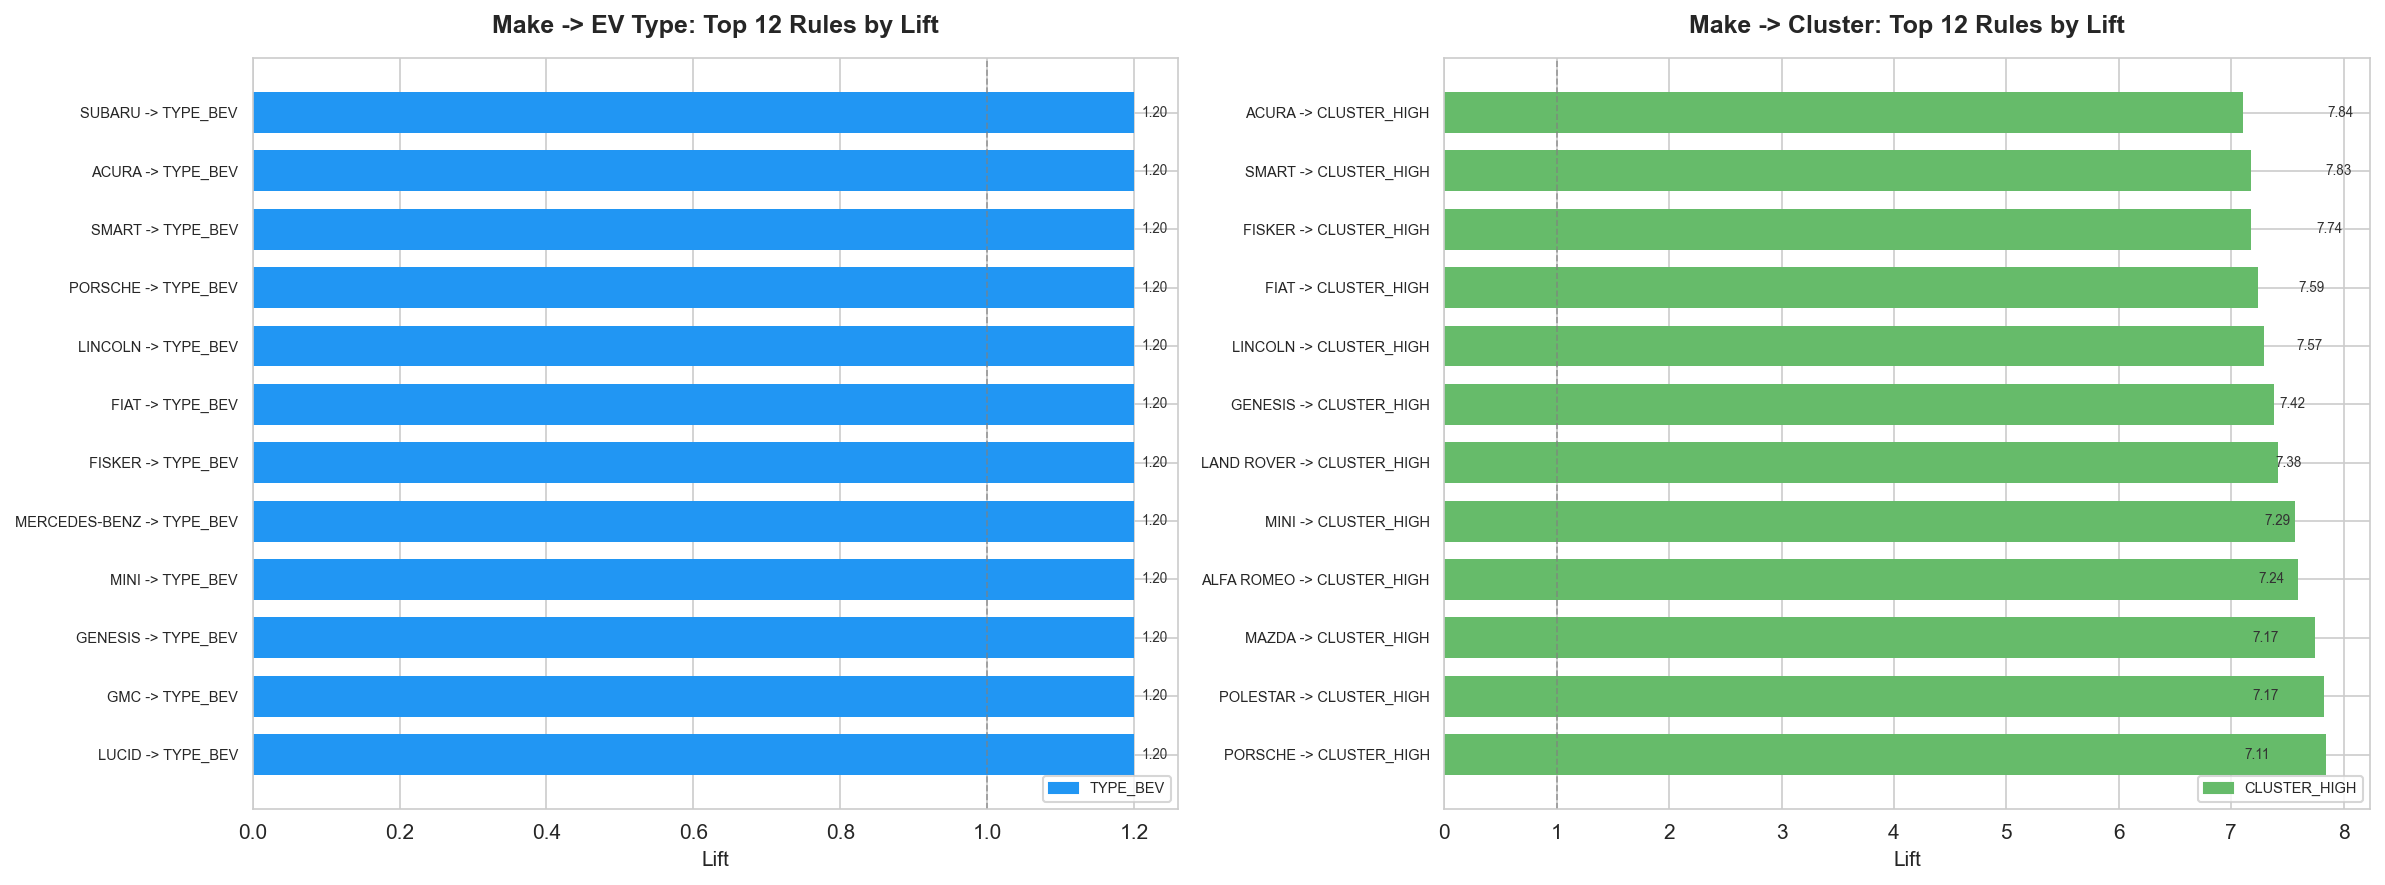

Figure saved: outputs/figures/make_type_cluster_rules.png


In [10]:
# Figure 3: Make -> EV Type and Make -> Cluster top rules side by side
top_type = type_rules.nlargest(12, 'lift')
top_cluster = cluster_rules.nlargest(12, 'lift')

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, data, title_text, color_a, color_b in [
    (axes[0], top_type, 'Make -> EV Type: Top 12 Rules by Lift', '#2196F3', '#FF7043'),
    (axes[1], top_cluster, 'Make -> Cluster: Top 12 Rules by Lift', '#66BB6A', '#AB47BC')
]:
    unique_consequents = data['consequents_str'].unique()
    palette = {c: color_a if i == 0 else color_b for i, c in enumerate(unique_consequents)}
    bar_colors = [palette.get(c, '#999999') for c in data['consequents_str']]

    labels = [f"{r['antecedents_str']} -> {r['consequents_str']}" for _, r in data.iterrows()]
    labels = [l[:60] + '...' if len(l) > 60 else l for l in labels]

    bars = ax.barh(range(len(data)), data['lift'].values, color=bar_colors[::-1], edgecolor='none', height=0.7)
    ax.set_yticks(range(len(data)))
    ax.set_yticklabels(labels[::-1], fontsize=7)
    ax.set_xlabel('Lift', fontsize=10)
    ax.set_title(title_text, fontweight='bold', pad=12)
    ax.axvline(1.0, color='gray', linestyle='--', linewidth=0.8, alpha=0.7)

    for i, (bar, val) in enumerate(zip(bars, data['lift'].values[::-1])):
        ax.text(val + 0.01, bar.get_y() + bar.get_height() / 2,
                f'{val:.2f}', va='center', fontsize=6.5, color='#333333')

    from matplotlib.patches import Patch
    legend_patches = [Patch(color=color, label=label) for label, color in palette.items()]
    ax.legend(handles=legend_patches, fontsize=7, loc='lower right')

plt.tight_layout()
plt.savefig('outputs/figures/make_type_cluster_rules.png', bbox_inches='tight')
plt.show()
print('Figure saved: outputs/figures/make_type_cluster_rules.png')

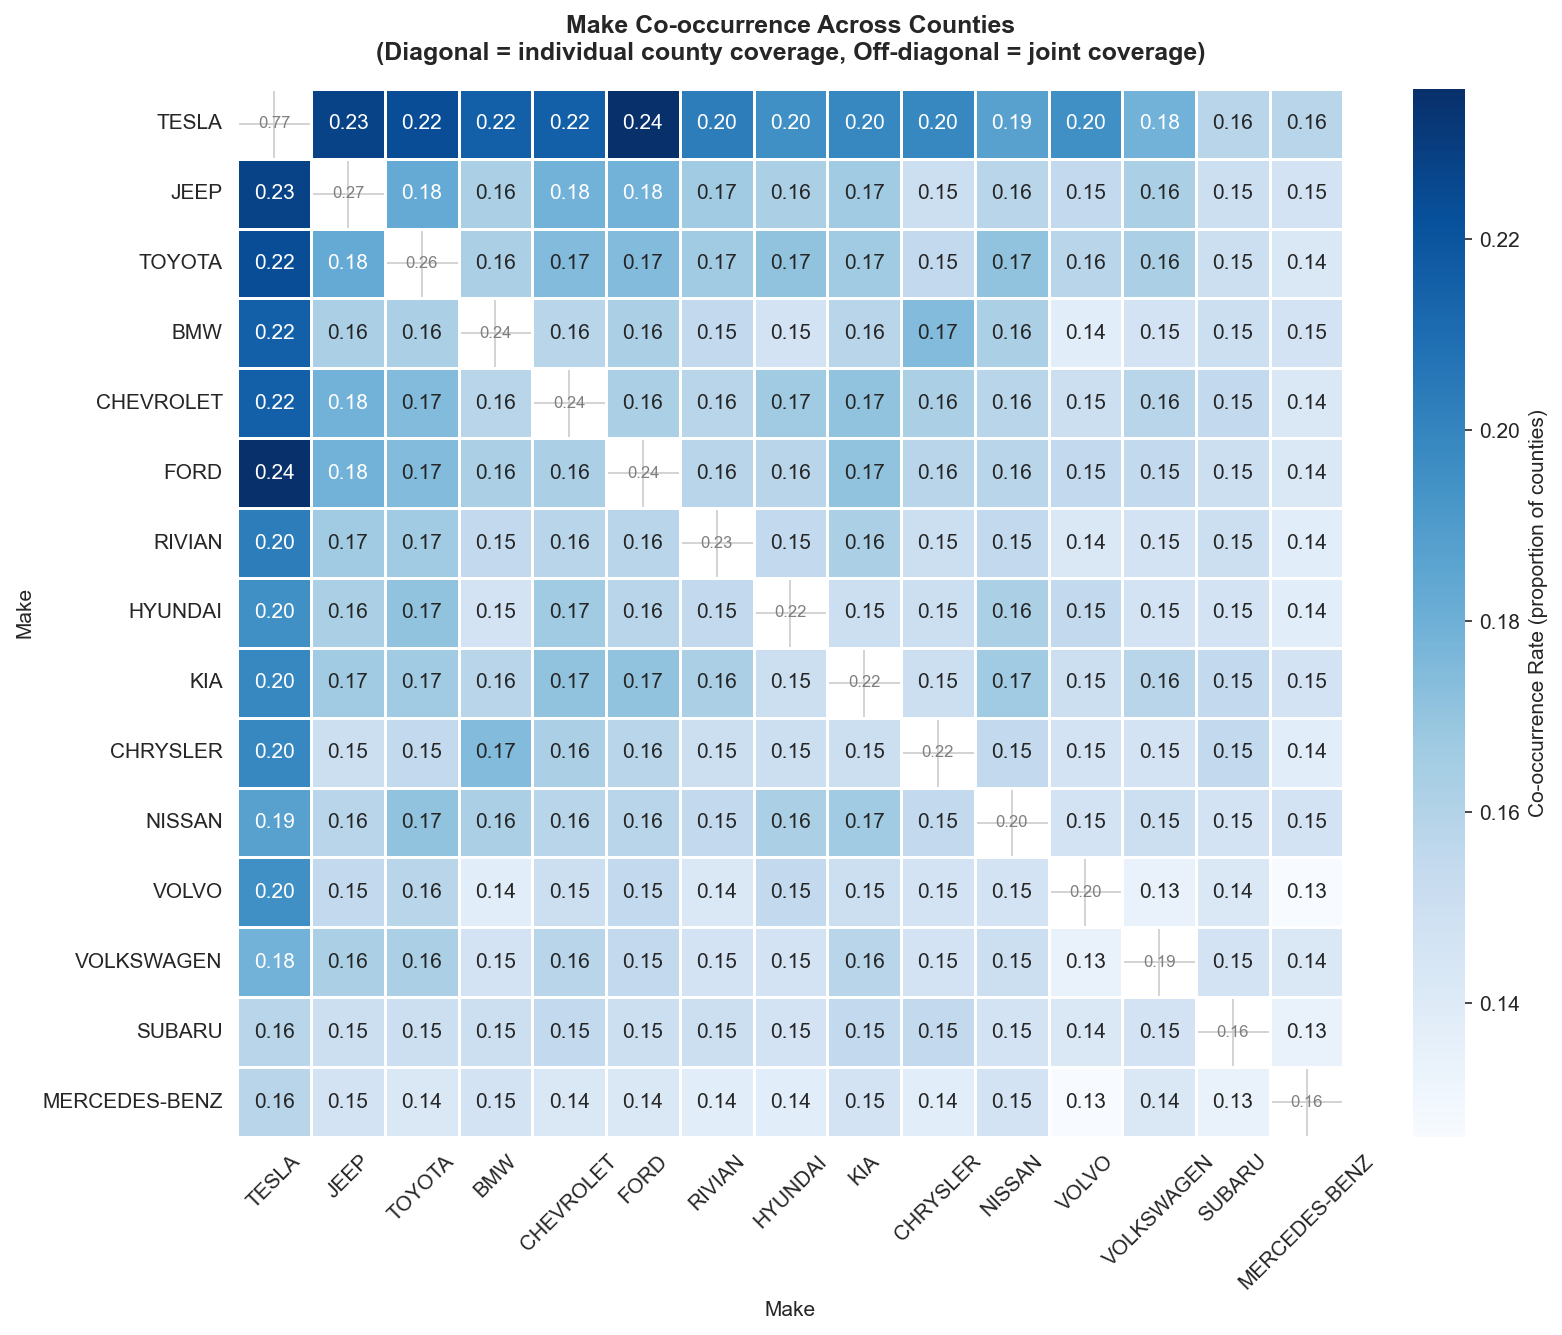

Figure saved: outputs/figures/make_cooccurrence_heatmap.png


In [11]:
# Figure 4: Make co-occurrence heatmap for top 15 makes
top15_makes = item_support.head(15).index.tolist()
basket_top15 = basket_df[top15_makes]

# Build co-occurrence matrix: proportion of counties containing both make A and make B
cooccurrence = pd.DataFrame(index=top15_makes, columns=top15_makes, dtype=float)

for make_a in top15_makes:
    for make_b in top15_makes:
        if make_a == make_b:
            cooccurrence.loc[make_a, make_b] = basket_top15[make_a].mean()
        else:
            cooccurrence.loc[make_a, make_b] = (basket_top15[make_a] & basket_top15[make_b]).mean()

cooccurrence = cooccurrence.astype(float)

fig, ax = plt.subplots(figsize=(11, 9))
mask = np.eye(len(top15_makes), dtype=bool)

sns.heatmap(
    cooccurrence, annot=True, fmt='.2f', cmap='Blues',
    mask=mask, ax=ax, linewidths=0.5, linecolor='white',
    cbar_kws={'label': 'Co-occurrence Rate (proportion of counties)'}
)
for i, make in enumerate(top15_makes):
    ax.text(i + 0.5, i + 0.5, f'{cooccurrence.loc[make, make]:.2f}',
            ha='center', va='center', fontsize=8, color='gray')

ax.set_title('Make Co-occurrence Across Counties\n(Diagonal = individual county coverage, Off-diagonal = joint coverage)',
             fontweight='bold', pad=14)
ax.set_xlabel('Make', fontsize=10)
ax.set_ylabel('Make', fontsize=10)
ax.tick_params(axis='x', rotation=45)
ax.tick_params(axis='y', rotation=0)

plt.tight_layout()
plt.savefig('outputs/figures/make_cooccurrence_heatmap.png', bbox_inches='tight')
plt.show()
print('Figure saved: outputs/figures/make_cooccurrence_heatmap.png')

In [12]:
# Save all rules to CSV
rules_export = rules_str[['antecedents_str', 'consequents_str', 'support', 'confidence', 'lift', 'leverage', 'conviction']].copy()
rules_export.columns = ['Antecedents', 'Consequents', 'Support', 'Confidence', 'Lift', 'Leverage', 'Conviction']
rules_export = rules_export.sort_values('Lift', ascending=False).reset_index(drop=True)
rules_export.to_csv('outputs/results/association_rules.csv', index=False)

type_export = type_rules[['antecedents_str', 'consequents_str', 'support', 'confidence', 'lift']].copy()
type_export.columns = ['Antecedents', 'Consequents', 'Support', 'Confidence', 'Lift']
type_export.to_csv('outputs/results/association_rules_type.csv', index=False)

cluster_export = cluster_rules[['antecedents_str', 'consequents_str', 'support', 'confidence', 'lift']].copy()
cluster_export.columns = ['Antecedents', 'Consequents', 'Support', 'Confidence', 'Lift']
cluster_export.to_csv('outputs/results/association_rules_cluster.csv', index=False)

print('Results saved:')
print(f'  outputs/results/association_rules.csv  ({len(rules_export)} rules)')
print(f'  outputs/results/association_rules_type.csv  ({len(type_export)} rules)')
print(f'  outputs/results/association_rules_cluster.csv  ({len(cluster_export)} rules)')

Results saved:
  outputs/results/association_rules.csv  (1240 rules)
  outputs/results/association_rules_type.csv  (35 rules)
  outputs/results/association_rules_cluster.csv  (37 rules)


In [13]:
# Summary of key findings for report reference
print('=== ASSOCIATION RULES MODULE — KEY FINDINGS SUMMARY ===')
print()
print(f'Transaction basket: {len(county_makes)} counties, {basket_df.shape[1]} unique makes')
print(f'Minimum support threshold: 0.05 (present in at least 5% of counties)')
print(f'Total frequent itemsets: {len(frequent_itemsets)}')
print(f'Total rules (lift >= 1.0): {len(rules)}')
print()
print('--- Make Co-occurrence ---')
print(f'Tesla county coverage: {item_support["TESLA"]:.1%}')
print(f'Top non-Tesla co-occurring pair (by lift):')
top_nt = non_tesla_rules.iloc[0]
print(f'  {top_nt["antecedents_str"]} -> {top_nt["consequents_str"]}  (lift={top_nt["lift"]:.3f}, conf={top_nt["confidence"]:.3f})')
print()
print('--- Make -> EV Type ---')
print(f'Rules predicting TYPE_PHEV: {(type_rules["consequents_str"] == "TYPE_PHEV").sum()}')
print(f'Rules predicting TYPE_BEV: {(type_rules["consequents_str"] == "TYPE_BEV").sum()}')
phev_rules = type_rules[type_rules['consequents_str'] == 'TYPE_PHEV']
if len(phev_rules) > 0:
    top_phev = phev_rules.iloc[0]
    print(f'Strongest PHEV predictor: {top_phev["antecedents_str"]}  (lift={top_phev["lift"]:.3f}, conf={top_phev["confidence"]:.3f})')
print()
print('--- Make -> Cluster ---')
for cluster_item in cluster_rules['consequents_str'].unique():
    subset = cluster_rules[cluster_rules['consequents_str'] == cluster_item]
    if len(subset) > 0:
        top_rule = subset.iloc[0]
        print(f'Strongest predictor of {cluster_item}: {top_rule["antecedents_str"]}  (lift={top_rule["lift"]:.3f}, conf={top_rule["confidence"]:.3f})')

=== ASSOCIATION RULES MODULE — KEY FINDINGS SUMMARY ===

Transaction basket: 246 counties, 47 unique makes
Minimum support threshold: 0.05 (present in at least 5% of counties)
Total frequent itemsets: 656
Total rules (lift >= 1.0): 1240

--- Make Co-occurrence ---
Tesla county coverage: 76.8%
Top non-Tesla co-occurring pair (by lift):
  JAGUAR -> ACURA  (lift=10.696, conf=1.000)

--- Make -> EV Type ---
Rules predicting TYPE_PHEV: 1
Rules predicting TYPE_BEV: 34
Strongest PHEV predictor: JEEP  (lift=1.182, conf=0.197)

--- Make -> Cluster ---
Strongest predictor of CLUSTER_HIGH: ACURA  (lift=7.843, conf=0.957)
Strongest predictor of CLUSTER_BEV_LOW: TESLA  (lift=1.101, conf=0.698)
Strongest predictor of CLUSTER_PHEV_LOW: TOYOTA  (lift=1.026, conf=0.246)
